# Blinkit Retail Analysis

**Problem statement:** Revenue in Apr–Oct 2024 fell about 6.8% against Apr–Oct 2023. Which product categories drove the decline, can delivery performance, customer ratings or stock damage explain it, and which categories should the business investigate first?

**Scope:** Apr–Oct 2023 vs Apr–Oct 2024 (partial months excluded). Revenue = quantity × unit price, because `order_total` does not reconcile with order items.



## 1. Load the data

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAW = "../data/raw/"
orders   = pd.read_csv(RAW + "blinkit_orders.csv", parse_dates=["order_date"])
items    = pd.read_csv(RAW + "blinkit_order_items.csv")
products = pd.read_csv(RAW + "blinkit_products.csv")
orders.shape, items.shape, products.shape

((5000, 10), (5000, 4), (268, 10))

> **Takeaway:** Loaded 5,000 orders and order items and 268 products; the row counts match the SQL tables.

## 2.Build the analysis table

In [4]:
df = (items.merge(orders[["order_id", "order_date"]], on="order_id")
           .merge(products[["product_id", "category"]], on="product_id"))
df["revenue"] = df["quantity"] * df["unit_price"]      # our revenue definition
df["year"]  = df["order_date"].dt.year
df["month"] = df["order_date"].dt.month

apr_oct = df[df["month"].between(4, 10)].copy()        # drops partial Mar-23 and Nov-24
apr_oct.groupby("year").agg(orders=("order_id", "nunique"), revenue=("revenue", "sum"))

,orders,revenue
year,,
2023,1791,1834519.07
2024,1753,1709920.91


> **Takeaway:** Orders fell from 1,791 to 1,753 and revenue from 1,834,519 to 1,709,921 (−6.8%). Revenue fell much more than orders, so units per order or prices also changed.

## 3. Category revenue change

In [5]:
cat = apr_oct.pivot_table(index="category", columns="year", values="revenue", aggfunc="sum")
cat["pct_change"] = (cat[2024] / cat[2023] - 1) * 100
cat = cat.sort_values("pct_change")
cat.round(1)

year,2023,2024,pct_change
category,,,
Fruits & Vegetables,246212.3,173057.3,-29.7
Cold Drinks & Juices,159777.5,128076.6,-19.8
Personal Care,151410.9,132538.6,-12.5
Baby Care,132992.1,117492.6,-11.7
Instant & Frozen Food,117199.6,109782.4,-6.3
Pharmacy,210314.7,199840.0,-5.0
Dairy & Breakfast,234588.5,228933.3,-2.4
Grocery & Staples,116805.8,119339.4,2.2
Pet Care,188051.2,196127.0,4.3


In [ ]:
vol = (apr_oct.groupby(["category", "year"])
       .agg(orders=("order_id", "nunique"), units=("quantity", "sum"),
            avg_unit_price=("unit_price", "mean")).round(2))
vol.loc[["Fruits & Vegetables", "Cold Drinks & Juices"]]

> **Takeaway:** Fruits & Vegetables (−29.7%) and Cold Drinks & Juices (−19.8%) fell the most, then Personal Care (−12.5%) and Baby Care (−11.7%). Household Care (+12.3%) and Snacks (+7.1%) grew most.

## 4. Revenue change chart

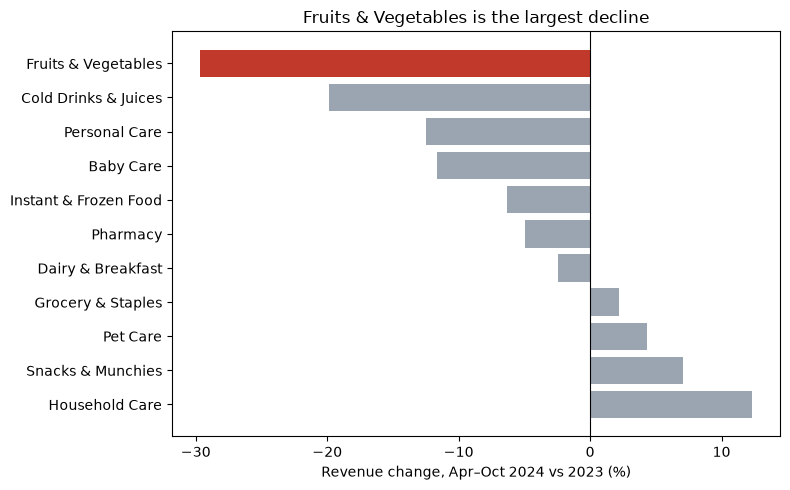

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
colors = ["#c0392b" if c == "Fruits & Vegetables" else "#9aa5b1" for c in cat.index]
ax.barh(cat.index, cat["pct_change"], color=colors)
ax.axvline(0, color="black", lw=0.8)
ax.invert_yaxis()
ax.set_xlabel("Revenue change, Apr–Oct 2024 vs 2023 (%)")
ax.set_title("Fruits & Vegetables is the largest decline")
plt.tight_layout()
plt.savefig("../images/category_change.png", dpi=150)
plt.show()

> **Takeaway:** Fruits & Vegetables is the largest decline, about 10 points ahead of the next category.

## 5. Is the change more than luck? (permutation test)

With only 120–220 orders per category-year, a large drop could be random variation. To check, I pooled each category's order lines from both years, randomly reassigned them to two groups of the original sizes 10,000 times, and counted how often a change at least as big as the real one appeared (the p-value). A small p-value means the change is unlikely to be luck.

In [7]:
rng = np.random.default_rng(42)

def perm_test(g, n_shuffles=10_000):
    rev = g["revenue"].to_numpy()
    is_24 = (g["year"] == 2024).to_numpy()
    observed = rev[is_24].sum() / rev[~is_24].sum() - 1
    n24 = is_24.sum()
    hits = 0
    for _ in range(n_shuffles):
        mask = np.zeros(len(rev), dtype=bool)
        mask[rng.permutation(len(rev))[:n24]] = True       # random "2024" lines
        change = rev[mask].sum() / rev[~mask].sum() - 1
        hits += abs(change) >= abs(observed)
    return observed * 100, (hits + 1) / (n_shuffles + 1)   # +1 avoids p = 0

res = {c: perm_test(g) for c, g in apr_oct.groupby("category")}
pvals = pd.DataFrame(res, index=["pct_change", "p_value"]).T.sort_values("pct_change")
pvals.round(3)

,pct_change,p_value
Fruits & Vegetables,-29.712,0.002
Cold Drinks & Juices,-19.841,0.190
Personal Care,-12.464,0.323
Baby Care,-11.654,0.425
Instant & Frozen Food,-6.329,0.786
Pharmacy,-4.980,0.583
Dairy & Breakfast,-2.411,0.924
Grocery & Staples,2.169,0.810
Pet Care,4.294,0.957
Snacks & Munchies,7.095,0.818


> **Takeaway:** Only Fruits & Vegetables (p ≈ 0.002) is clearly more than random variation, and it holds up even with a strict correction for testing 11 categories (0.05 ÷ 11 ≈ 0.0045). Cold Drinks (p ≈ 0.19) and the rest could be luck with samples this small.

## 6. Fruits & Vegetables by month

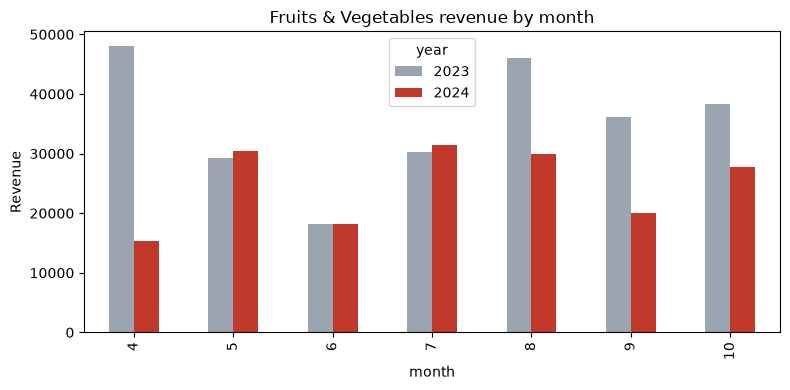

In [8]:
fv = apr_oct[apr_oct["category"] == "Fruits & Vegetables"]
monthly = fv.pivot_table(index="month", columns="year", values="revenue", aggfunc="sum")
ax = monthly.plot(kind="bar", figsize=(8, 4), color=["#9aa5b1", "#c0392b"])
ax.set_ylabel("Revenue")
ax.set_title("Fruits & Vegetables revenue by month")
plt.tight_layout()
plt.savefig("../images/fv_monthly.png", dpi=150)
plt.show()

> **Takeaway:** May to July were flat; the fall comes from April and Aug–Oct. April 2023 was unusually high, but excluding April the drop is still about −20% (198,105 → 157,798). Monthly samples are small (16–35 orders), so treat this as descriptive.

## 7. Export for Power BI

In [9]:
os.makedirs("../data/processed", exist_ok=True)
out = cat.rename(columns={2023: "rev_2023", 2024: "rev_2024"}).join(pvals["p_value"])
out.reset_index().to_csv("../data/processed/category_yoy.csv", index=False)
monthly.reset_index().to_csv("../data/processed/fv_monthly.csv", index=False)

## Conclusion

Fruits & Vegetables is the only category whose revenue decline (−29.7%, Apr–Oct 2024 vs 2023) is clearly larger than random variation. It comes from fewer orders, fewer units and lower average prices, concentrated in April and Aug–Oct. Delivery on-time rate for this category fell about 9 points but ratings did not drop, and stock damage does not explain the decline. The available data cannot identify the cause, so the business should investigate stock availability, pricing and discounts, and supply in April 2024 and Aug–Oct 2024.

## Limitations
- Small sample: 120–220 orders per category-year, and 16–35 per month for one category.
- Each order has one item, and `order_total` does not reconcile with item values.
- Many relationships in the data look random (for example, delivery delays do not affect ratings), so it appears to be a sample dataset. These findings describe this dataset, not Blinkit's real business.